<a href="https://colab.research.google.com/github/devcodes28/AI-ML-Lab-24CSP503/blob/main/Kernal_Machines_and_Instant_Based_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Medical Insurance: Regression & Classification with Ensembles
**Dataset:** Kaggle `mirichoi0218/insurance` (1,338 rows: age, sex, bmi, children, smoker, region, charges)

| Task | Target |
|---|---|
| Regression | `charges` (insurance cost) |
| Classification | `high_cost` (1 if charges > median) |

**Models:** Decision Tree · Random Forest · SVM  
**Ensembles:** Bagging · Boosting · Stacking

## 1. Install & Import

In [1]:
!pip install -q kagglehub seaborn

In [2]:
import glob, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.svm import SVR, SVC
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              BaggingRegressor, BaggingClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier,
                              StackingRegressor, StackingClassifier)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

## 2. Load Dataset

In [3]:
try:
    import kagglehub
    path = kagglehub.dataset_download("mirichoi0218/insurance")
    df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])
except Exception as e:  # fallback mirror of the same dataset
    print("Kaggle load failed, using GitHub mirror:", e)
    df = pd.read_csv("https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv")
df.head()

Using Colab cache for faster access to the 'insurance' dataset.


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Part 1 — Data Preprocessing
## 3. Inspect Data (types, missing values, duplicates)

In [4]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values per column:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


## 4. Clean Data (remove duplicates & missing values)

In [5]:
df = df.drop_duplicates().dropna().reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (1337, 7)


## 5. Outlier Detection (boxplots + IQR rule)

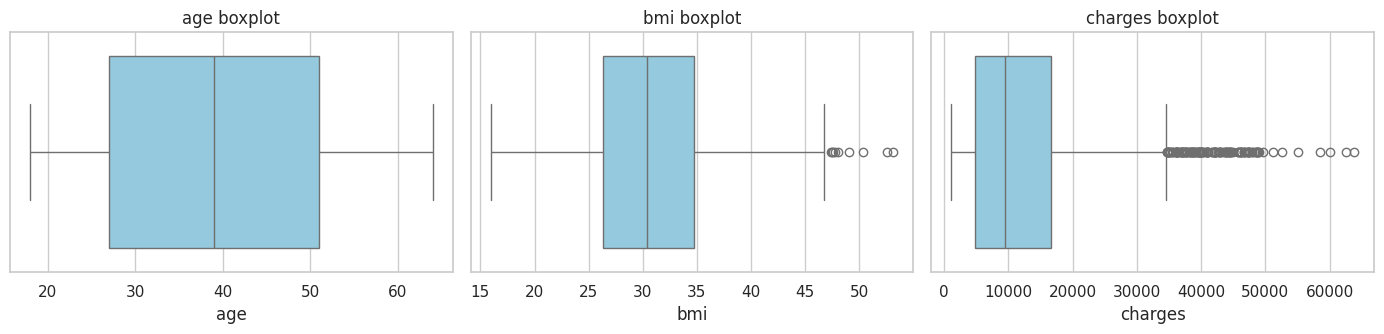

BMI outliers: 9 rows (bounds 13.7 – 47.3)


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ["age", "bmi", "charges"]):
    sns.boxplot(x=df[c], ax=a, color="skyblue"); a.set_title(f"{c} boxplot")
plt.tight_layout(); plt.show()

def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

lo, hi = iqr_bounds(df["bmi"])
print(f"BMI outliers: {((df.bmi < lo) | (df.bmi > hi)).sum()} rows (bounds {lo:.1f} – {hi:.1f})")

## 6. Handle Outliers
BMI is **capped** (winsorized) at the IQR bounds. The target `charges` is left untouched — high charges are real (mostly smokers), not errors.

In [7]:
df["bmi"] = df["bmi"].clip(lo, hi)

## 7. Create Classification Target

In [8]:
df["high_cost"] = (df["charges"] > df["charges"].median()).astype(int)
print(df["high_cost"].value_counts())

high_cost
0    669
1    668
Name: count, dtype: int64


## 8. Exploratory Graphs

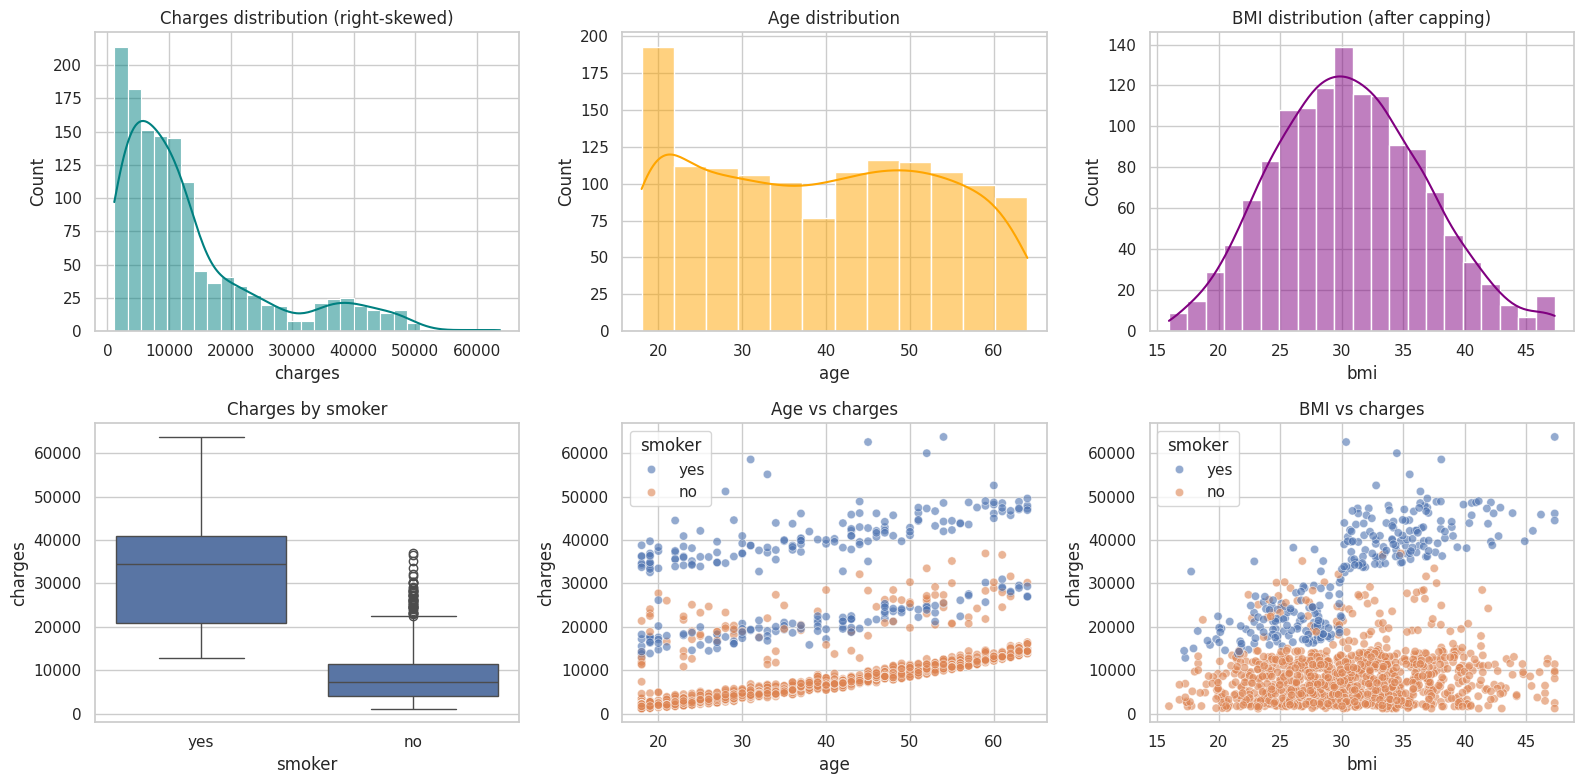

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df["charges"], kde=True, ax=ax[0,0], color="teal").set_title("Charges distribution (right-skewed)")
sns.histplot(df["age"], kde=True, ax=ax[0,1], color="orange").set_title("Age distribution")
sns.histplot(df["bmi"], kde=True, ax=ax[0,2], color="purple").set_title("BMI distribution (after capping)")
sns.boxplot(data=df, x="smoker", y="charges", ax=ax[1,0]).set_title("Charges by smoker")
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", ax=ax[1,1], alpha=.6).set_title("Age vs charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", ax=ax[1,2], alpha=.6).set_title("BMI vs charges")
plt.tight_layout(); plt.show()

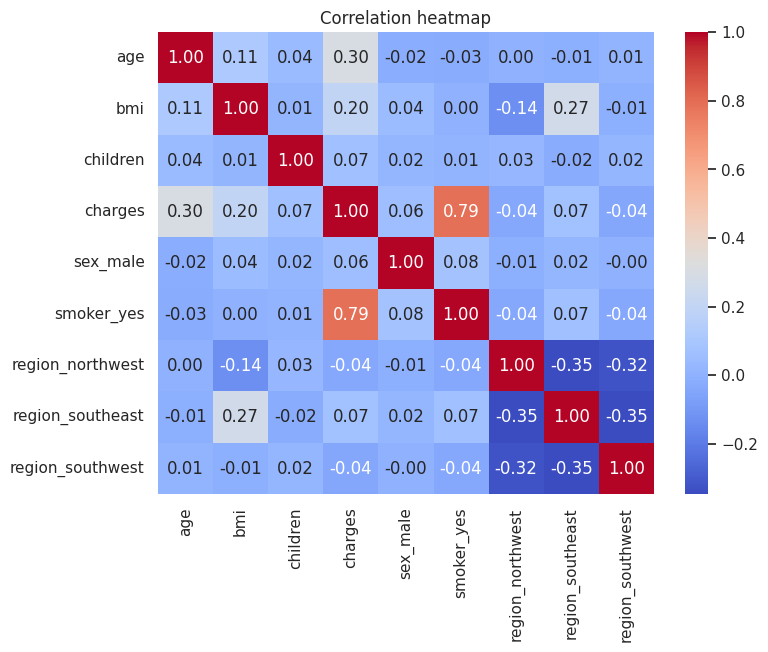

In [10]:
# Correlation heatmap (categoricals encoded just for this plot)
enc = pd.get_dummies(df.drop(columns="high_cost"), drop_first=True).astype(float)
plt.figure(figsize=(8, 6))
sns.heatmap(enc.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

## 9. Train/Test Split
Split **before** scaling/encoding so no information from the test set leaks into preprocessing.

In [11]:
X = df.drop(columns=["charges", "high_cost"])
y_reg, y_clf = df["charges"], df["high_cost"]

X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf)
print("Train:", X_tr.shape, "| Test:", X_te.shape)

Train: (1069, 6) | Test: (268, 6)


## 10. Encoding & Scaling (ColumnTransformer)
- **Numeric** (`age`, `bmi`, `children`) → StandardScaler  
- **Categorical** (`sex`, `smoker`, `region`) → One-Hot Encoding

In [12]:
num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]

def make_pre():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first"), cat_cols),
    ])

# Preview of the transformed training data
pre = make_pre().fit(X_tr)
pd.DataFrame(pre.transform(X_tr), columns=pre.get_feature_names_out()).head()

,num__age,num__bmi,num__children,cat__sex_male,cat__smoker_yes,cat__region_northwest,cat__region_southeast,cat__region_southwest
0,1.551466,0.531870,-0.916189,1.0,0.0,0.0,0.0,0.0
1,-0.014180,-1.220619,1.536413,0.0,0.0,0.0,0.0,0.0
2,1.409135,-0.860733,-0.916189,1.0,0.0,1.0,0.0,0.0
3,-1.010500,-1.117677,3.171481,1.0,0.0,0.0,0.0,1.0
4,-0.583506,-0.344375,-0.098655,1.0,0.0,1.0,0.0,0.0


# Part 2 — Regression (predict `charges`)
## 11. Base Models + Ensembles
- **Bagging:** many Decision Trees on bootstrap samples  
- **Boosting:** Gradient Boosting (trees fitted sequentially on errors)  
- **Stacking:** DT + RF + SVR combined by a Ridge meta-model  

> SVR needs a scaled target, so it's wrapped in `TransformedTargetRegressor`.

In [13]:
dt  = DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=SEED)
rf  = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
svr = TransformedTargetRegressor(SVR(C=3), transformer=StandardScaler())

reg_estimators = {
    # --- base models ---
    "Decision Tree": dt,
    "Random Forest": rf,
    "SVR": svr,
    # --- ensembles ---
    "Bagging (DT)":  BaggingRegressor(estimator=dt, n_estimators=100, random_state=SEED, n_jobs=-1),
    "Boosting (GB)": GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=SEED),
    "Stacking": StackingRegressor([("dt", dt), ("rf", rf), ("svr", svr)], final_estimator=Ridge(), cv=5, n_jobs=-1),
}
reg_models = {n: make_pipeline(make_pre(), m) for n, m in reg_estimators.items()}

## 12. Train & Evaluate

In [14]:
rows, reg_pred = [], {}
for name, m in reg_models.items():
    m.fit(X_tr, yr_tr)
    p = m.predict(X_te); reg_pred[name] = p
    rows.append({"Model": name,
                 "R2": r2_score(yr_te, p),
                 "RMSE": np.sqrt(mean_squared_error(yr_te, p)),
                 "MAE": mean_absolute_error(yr_te, p),
                 "CV R2 (5-fold)": cross_val_score(m, X_tr, yr_tr, cv=5, scoring="r2", n_jobs=-1).mean()})
reg_res = pd.DataFrame(rows).set_index("Model").round(3)
reg_res

,R2,RMSE,MAE,CV R2 (5-fold)
Model,,,,
Decision Tree,0.874,4689.765,2646.256,0.846
Random Forest,0.878,4607.332,2515.603,0.849
SVR,0.849,5139.076,2744.085,0.831
Bagging (DT),0.880,4574.156,2521.895,0.852
Boosting (GB),0.880,4571.414,2419.783,0.849
Stacking,0.879,4597.248,2526.540,0.851


## 13. Regression Graphs

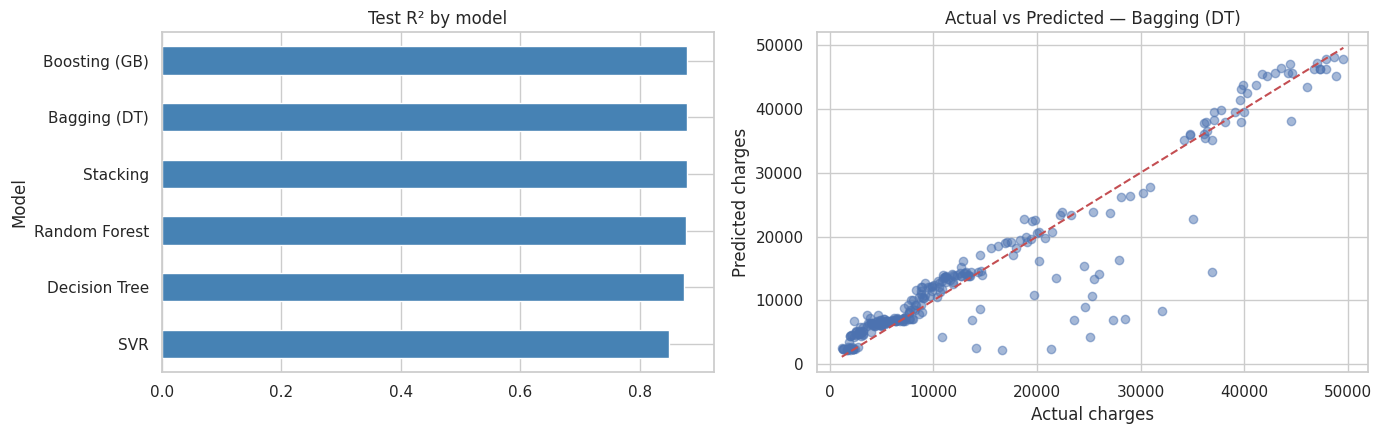

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
reg_res["R2"].sort_values().plot.barh(ax=ax[0], color="steelblue", title="Test R² by model")
best = reg_res["R2"].idxmax()
ax[1].scatter(yr_te, reg_pred[best], alpha=.5)
lim = [yr_te.min(), yr_te.max()]; ax[1].plot(lim, lim, "r--")
ax[1].set(title=f"Actual vs Predicted — {best}", xlabel="Actual charges", ylabel="Predicted charges")
plt.tight_layout(); plt.show()

# Part 3 — Classification (predict `high_cost`)
## 14. Base Models + Ensembles

In [17]:
dtc = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=SEED)
rfc = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
svc = SVC(C=3, probability=True, random_state=SEED)

clf_estimators = {
    "Decision Tree": dtc,
    "Random Forest": rfc,
    "SVM": svc,
    "Bagging (DT)":  BaggingClassifier(estimator=dtc, n_estimators=100, random_state=SEED, n_jobs=-1),
    "Boosting (GB)": GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=SEED),
    "Stacking": StackingClassifier([("dt", dtc), ("rf", rfc), ("svm", svc)],
                                   final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1),
}
clf_models = {n: make_pipeline(make_pre(), m) for n, m in clf_estimators.items()}

## 15. Train & Evaluate

In [18]:
rows, clf_pred = [], {}
for name, m in clf_models.items():
    m.fit(X_tr, yc_tr)
    p = m.predict(X_te); clf_pred[name] = p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yc_te, p),
                 "F1": f1_score(yc_te, p),
                 "ROC-AUC": roc_auc_score(yc_te, m.predict_proba(X_te)[:, 1]),
                 "CV Acc (5-fold)": cross_val_score(m, X_tr, yc_tr, cv=5, scoring="accuracy", n_jobs=-1).mean()})
clf_res = pd.DataFrame(rows).set_index("Model").round(3)
clf_res

,Accuracy,F1,ROC-AUC,CV Acc (5-fold)
Model,,,,
Decision Tree,0.937,0.933,0.944,0.916
Random Forest,0.937,0.935,0.944,0.929
SVM,0.940,0.939,0.966,0.923
Bagging (DT),0.937,0.934,0.949,0.921
Boosting (GB),0.937,0.934,0.952,0.927
Stacking,0.929,0.928,0.957,0.922


## 16. Classification Graphs

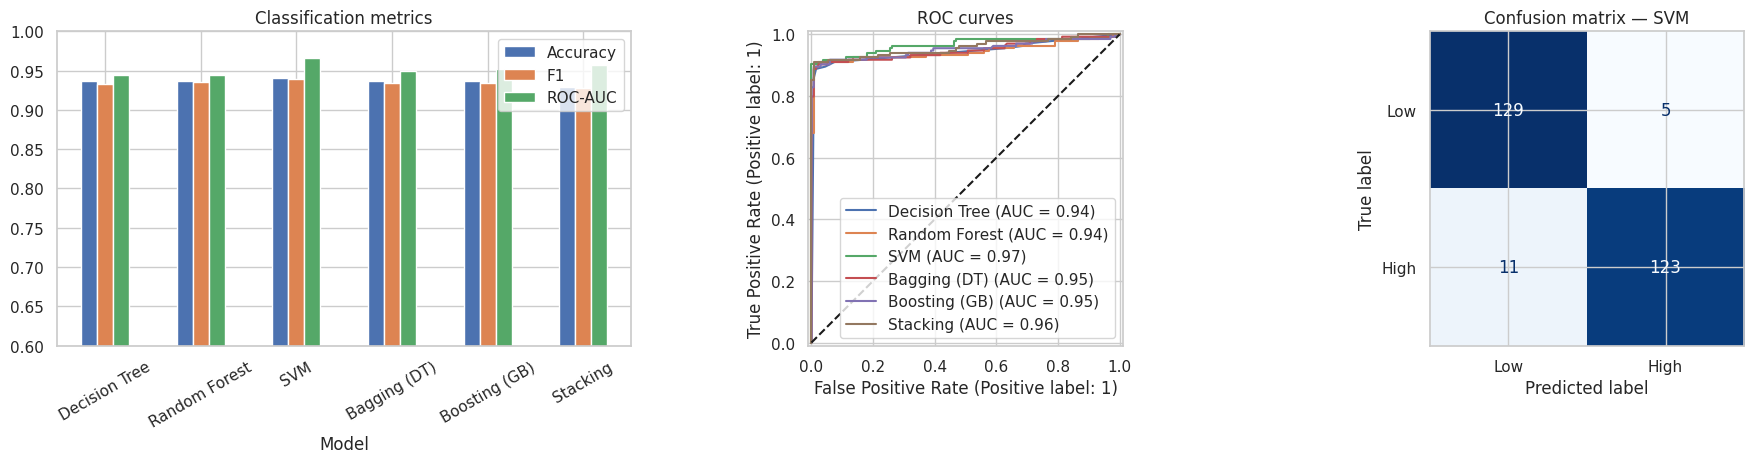

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
clf_res[["Accuracy", "F1", "ROC-AUC"]].plot.bar(ax=ax[0], rot=30, title="Classification metrics")
ax[0].set_ylim(0.6, 1)
for name, m in clf_models.items():
    RocCurveDisplay.from_estimator(m, X_te, yc_te, ax=ax[1], name=name)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curves")
bestc = clf_res["Accuracy"].idxmax()
ConfusionMatrixDisplay(confusion_matrix(yc_te, clf_pred[bestc]),
                       display_labels=["Low", "High"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title(f"Confusion matrix — {bestc}")
plt.tight_layout(); plt.show()

## 17. Decision Tree Visualization
The fitted trees have `max_depth=5`; only the **top 3 levels** are drawn so the plots stay readable. Each box shows the split rule, the number of samples, and the prediction (colour = value/class).

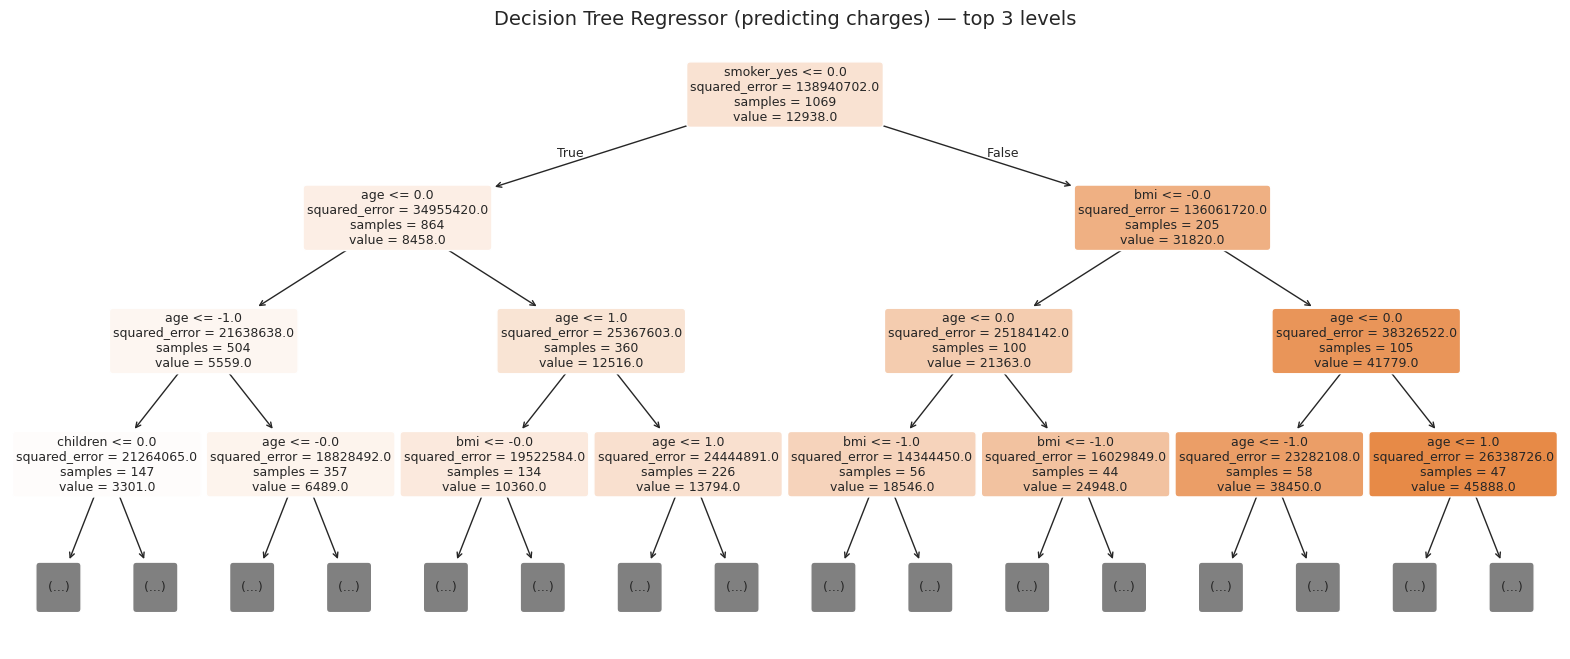

In [20]:
from sklearn.tree import plot_tree, export_text

feat_names = [n.split("__")[-1] for n in reg_models["Decision Tree"][0].get_feature_names_out()]

# --- Regression tree ---
plt.figure(figsize=(20, 8))
plot_tree(reg_models["Decision Tree"][-1], feature_names=feat_names, max_depth=3,
          filled=True, rounded=True, fontsize=9, precision=0)
plt.title("Decision Tree Regressor (predicting charges) — top 3 levels", fontsize=14)
plt.show()

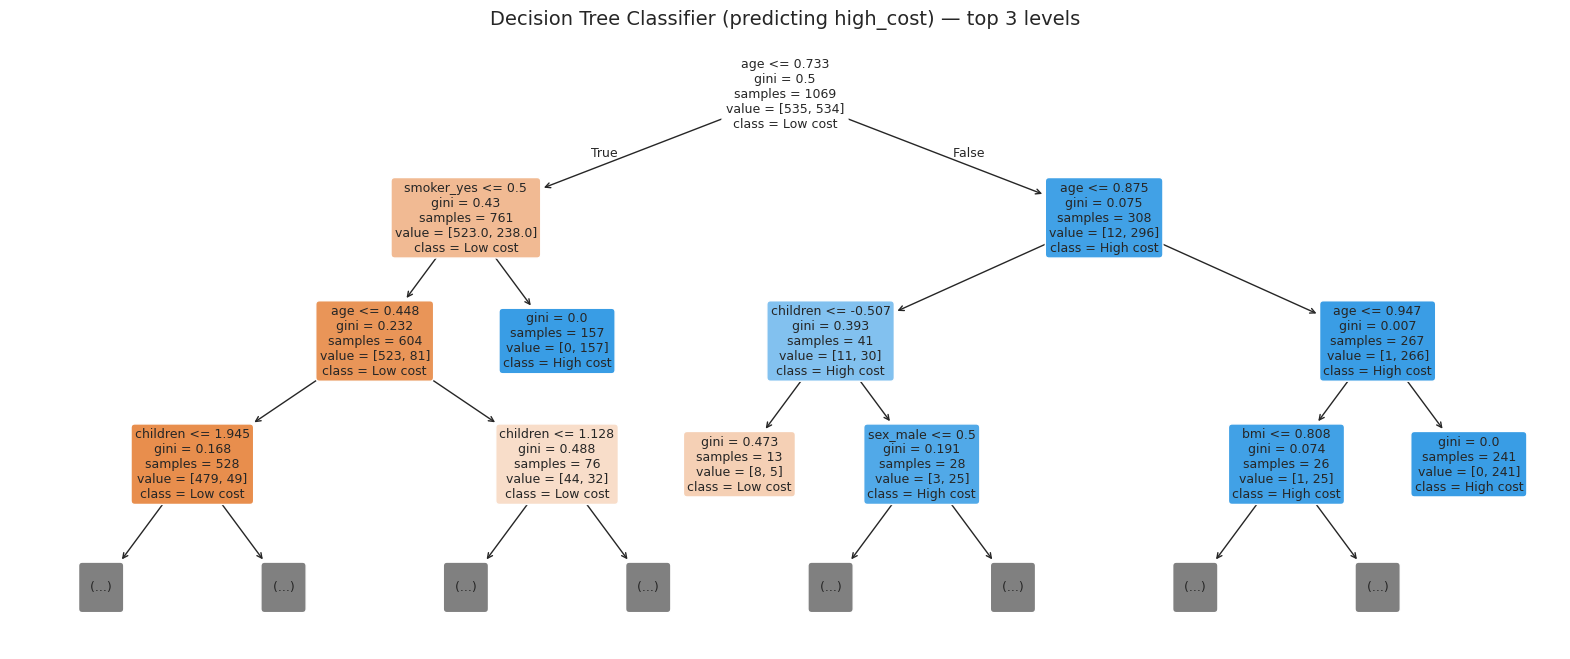

In [21]:
# --- Classification tree ---
plt.figure(figsize=(20, 8))
plot_tree(clf_models["Decision Tree"][-1], feature_names=feat_names, max_depth=3,
          class_names=["Low cost", "High cost"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree Classifier (predicting high_cost) — top 3 levels", fontsize=14)
plt.show()

**How to read it:** the root split is usually on `smoker_yes` (scaled values for `age`/`bmi` appear as standardized numbers, e.g. `age <= 0.1` means slightly above average age). Left branch = condition true.

## 18. Feature Importance (Random Forest Regressor)

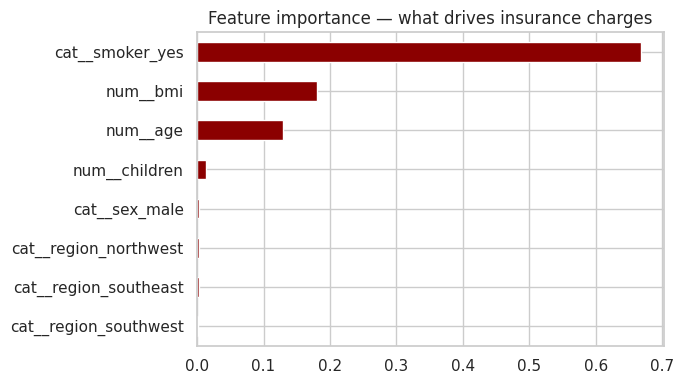

In [23]:
rf_pipe = reg_models["Random Forest"]
names = rf_pipe[0].get_feature_names_out()
imp = pd.Series(rf_pipe[-1].feature_importances_, index=names).sort_values()
imp.plot.barh(figsize=(7, 4), color="darkred", title="Feature importance — what drives insurance charges")
plt.tight_layout(); plt.show()

## 19. Final Summary

In [24]:
print("Best regression model:    ", reg_res["R2"].idxmax(), "| R² =", reg_res["R2"].max())
print("Best classification model:", clf_res["Accuracy"].idxmax(), "| Accuracy =", clf_res["Accuracy"].max())

Best regression model:     Bagging (DT) | R² = 0.88
Best classification model: SVM | Accuracy = 0.94
